# Multi-Head CNN Model 
F. Usshihab

Folder-label ECG version for **abnormal / borderline / normal** data.


## Imports


In [1]:
import os
import re
import json
import pickle
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

from sklearn.preprocessing import LabelEncoder, LabelBinarizer
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, BatchNormalization, MaxPooling1D, Flatten, Dense, Dropout, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

/Users/fahizzle/projects/github/mh-cnn-ekg/tf-env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
# Instead of an Excel input file, this version uses a root folder.
# Expected structure:
#
# data/
#   abnormal/
#     file1.csv
#   borderline/
#     file2.csv
#   normal/
#     file3.csv

# For local Jupyter / VS Code:
data_folder = "data"

# For Colab, change this to something like:
# data_folder = "/content/drive/MyDrive/ColabNotebooks/ECG/data"

CLASS_NAMES = ["abnormal", "borderline", "normal"]
FILE_EXTENSIONS = (".csv", ".txt", ".xlsx", ".xls")

# The uploaded sample has 8 leads per ECG timestep.
# Change to 12 if your real ECG files have 12 leads.
EXPECTED_LEADS = 8

# Every ECG must be the same length for CNN training.
FIXED_LENGTH = 3000

# If multiple files belong to the same subject/patient/record,
# use a regex that extracts the shared ID from each filename.
# Examples:
# GROUP_ID_REGEX = r"(ERNE\d+)"
# GROUP_ID_REGEX = r"(patient[_-]?\d+)"
# GROUP_ID_REGEX = r"(\d{8,})"
# If None, the full filename stem is used as the group ID.
GROUP_ID_REGEX = None

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

In [3]:
name = data_folder
print("Current data folder:", name)

# Optional Colab-style selector from the older notebook.
# Uncomment if you want interactive path selection.
# loxn = input('Are you running from your drive or your dads drive? (0=yours; 1=his; enter=use data_folder above)')
# if loxn == '0':
#     data_folder = '/content/drive/MyDrive/ColabNotebooks/ECG/data'
# elif loxn == '1':
#     data_folder = '/content/drive/MyDrive/Colab Notebooks/fahim/ECG/data'

DATA_ROOT = Path(data_folder)
print("Using DATA_ROOT:", DATA_ROOT)

Current data folder: data
Using DATA_ROOT: data


## Input Data Selection

In [4]:
# Use this cell in Google Colab only.
# from google.colab import drive
# drive.mount('/content/drive')

In [5]:
current_directory = os.getcwd()
print("Current directory:", current_directory)
print("DATA_ROOT exists:", DATA_ROOT.exists())

Current directory: /Users/fahizzle/projects/github/mh-cnn-ekg
DATA_ROOT exists: True


## Data Import

In [6]:
def infer_label_from_path(path, class_names=CLASS_NAMES):
    # Infer label from the folder name, for example data/abnormal/file.csv -> abnormal.
    lower_parts = [part.lower() for part in Path(path).parts]
    matches = [label for label in class_names if label.lower() in lower_parts]
    if len(matches) == 1:
        return matches[0]
    return None


def extract_group_id(path, group_id_regex=GROUP_ID_REGEX):
    # Extract split/group ID from the filename.
    # This replaces the old Parent Folder split variable while keeping the same notebook logic.
    stem = Path(path).stem
    if group_id_regex:
        match = re.search(group_id_regex, stem)
        if match:
            if match.groups():
                return match.group(1)
            return match.group(0)
        print(f"WARNING: GROUP_ID_REGEX did not match {stem!r}. Falling back to full filename stem.")
    return stem


all_files = []
for ext in FILE_EXTENSIONS:
    all_files.extend(DATA_ROOT.rglob(f"*{ext}"))

rows = []
skipped_files = []

with tqdm(total=len(all_files), desc="Discovering ECG files") as pbar:
    for path in sorted(all_files):
        label = infer_label_from_path(path)
        if label is None:
            skipped_files.append((str(path), "label folder not found"))
            pbar.update(1)
            continue

        rows.append({
            "File Path": str(path),
            "File Name": path.name,
            "Diagnosis": label,
            "Label Folder": label,
            "Parent Folder": extract_group_id(path),
        })
        pbar.update(1)

records_df = pd.DataFrame(rows)

print("Discovered files:", len(records_df))
if not records_df.empty:
    print(records_df["Diagnosis"].value_counts().reindex(CLASS_NAMES, fill_value=0))
    display(records_df.head())

if skipped_files:
    print("Skipped files during discovery:", len(skipped_files))
    print(skipped_files[:10])

if records_df.empty:
    raise RuntimeError(f"No ECG files were found under {DATA_ROOT}. Expected subfolders named {CLASS_NAMES}.")

Discovering ECG files: 100%|██████████| 26/26 [00:00<00:00, 34807.50it/s]

Discovered files: 26
Diagnosis
abnormal       7
borderline     9
normal        10
Name: count, dtype: int64


,File Path,File Name,Diagnosis,Label Folder,Parent Folder
0,data/abnormal/ANH1_2min_cranial_position.csv,ANH1_2min_cranial_position.csv,abnormal,abnormal,ANH1_2min_cranial_position
1,data/abnormal/CFA2_2min_cranial_position.csv,CFA2_2min_cranial_position.csv,abnormal,abnormal,CFA2_2min_cranial_position
2,data/abnormal/CFA33_2min_cranial_position.csv,CFA33_2min_cranial_position.csv,abnormal,abnormal,CFA33_2min_cranial_position
3,data/abnormal/CFA9_2min_cranial_position.csv,CFA9_2min_cranial_position.csv,abnormal,abnormal,CFA9_2min_cranial_position
4,data/abnormal/CKTC9_2min.csv,CKTC9_2min.csv,abnormal,abnormal,CKTC9_2min


In [7]:
# Save the manifest using pickle, similar to the original notebook.
pickle_file = "ecg_records_manifest.pickle"
with open(pickle_file, "wb") as f:
    pickle.dump(records_df, f)

records_df.to_csv("ecg_records_manifest.csv", index=False)
print("Saved:", pickle_file)
print("Saved: ecg_records_manifest.csv")

Saved: ecg_records_manifest.pickle
Saved: ecg_records_manifest.csv


## Post Pickle Running Point

In [8]:
# Start from here if the manifest was already created.
with open(pickle_file, "rb") as f:
    records_df = pickle.load(f)

records_df = records_df.reset_index(drop=True)
print(records_df.shape)
display(records_df.head())

(26, 5)


,File Path,File Name,Diagnosis,Label Folder,Parent Folder
0,data/abnormal/ANH1_2min_cranial_position.csv,ANH1_2min_cranial_position.csv,abnormal,abnormal,ANH1_2min_cranial_position
1,data/abnormal/CFA2_2min_cranial_position.csv,CFA2_2min_cranial_position.csv,abnormal,abnormal,CFA2_2min_cranial_position
2,data/abnormal/CFA33_2min_cranial_position.csv,CFA33_2min_cranial_position.csv,abnormal,abnormal,CFA33_2min_cranial_position
3,data/abnormal/CFA9_2min_cranial_position.csv,CFA9_2min_cranial_position.csv,abnormal,abnormal,CFA9_2min_cranial_position
4,data/abnormal/CKTC9_2min.csv,CKTC9_2min.csv,abnormal,abnormal,CKTC9_2min


## Head Activation/De-Activation

This section of the code is used to selectively activate and de-activate heads that will be used to train the model.

In [9]:
# ECG lead names for the uploaded sample are not provided as standard I/II/III/etc.
# So this notebook names them Lead_1, Lead_2, ..., Lead_N.

lead_names = [f"Lead_{i+1}" for i in range(EXPECTED_LEADS)]

# Activate all leads by default.
active_leads = lead_names.copy()

# Example: to use only the first two leads, uncomment:
# active_leads = ["Lead_1", "Lead_2"]

active_lead_indices = [lead_names.index(lead) for lead in active_leads]
print("Active leads:", active_leads)
print("Active lead indices:", active_lead_indices)

Active leads: ['Lead_1', 'Lead_2', 'Lead_3', 'Lead_4', 'Lead_5', 'Lead_6', 'Lead_7', 'Lead_8']
Active lead indices: [0, 1, 2, 3, 4, 5, 6, 7]


In [10]:
# Alternative head selections, similar to the original notebook style.

# active_leads = ["Lead_1"]
# active_leads = ["Lead_1", "Lead_2"]
active_leads = ["Lead_1", "Lead_2", "Lead_3", "Lead_4"]
# active_leads = ["Lead_1", "Lead_2", "Lead_3", "Lead_4", "Lead_5", "Lead_6", "Lead_7", "Lead_8"]

# If you edit active_leads here, re-run:
# active_lead_indices = [lead_names.index(lead) for lead in active_leads]

## Load and Filter Sheet

This version loads ECG files and filters to the activated ECG leads.

In [11]:
def parse_ecg_text(text, expected_leads=EXPECTED_LEADS):
    # Extract ECG data from awkward files where the ECG array is embedded like:
    # [[-75, 443, -586, ...], [-72, 341, -582, ...], ...]
    row_strings = re.findall(r"\[([^\[\]]+)\]", text, flags=re.S)

    rows = []
    for row_string in row_strings:
        nums = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", row_string)
        if len(nums) >= 2:
            rows.append([float(x) for x in nums])

    if not rows:
        raise ValueError("No ECG numeric rows were found.")

    if expected_leads is None:
        length_counts = Counter(len(r) for r in rows)
        expected_leads = length_counts.most_common(1)[0][0]

    rows = [r for r in rows if len(r) == expected_leads]
    if not rows:
        raise ValueError(f"No ECG rows matched expected_leads={expected_leads}.")

    return np.asarray(rows, dtype=np.float32)


def load_ecg_file(path, expected_leads=EXPECTED_LEADS):
    path = Path(path)
    suffix = path.suffix.lower()

    if suffix in [".xlsx", ".xls"]:
        df = pd.read_excel(path)
        if "ecg" in df.columns:
            text = "\n".join(df["ecg"].astype(str).tolist())
        else:
            text = "\n".join(df.astype(str).to_numpy().ravel().tolist())
    else:
        text = path.read_text(encoding="utf-8", errors="replace")

    return parse_ecg_text(text, expected_leads=expected_leads)


def zscore_per_lead(x, eps=1e-8):
    mean = x.mean(axis=0, keepdims=True)
    std = x.std(axis=0, keepdims=True)
    return (x - mean) / (std + eps)


def pad_or_truncate(x, fixed_length=FIXED_LENGTH):
    n_steps, n_leads = x.shape
    if n_steps == fixed_length:
        return x.astype(np.float32)
    if n_steps > fixed_length:
        return x[:fixed_length, :].astype(np.float32)
    padded = np.zeros((fixed_length, n_leads), dtype=np.float32)
    padded[:n_steps, :] = x
    return padded

## Train and Validation Data Isolation

In [12]:
# Manual split section, similar to the original notebook.
# Fill these with filename-derived Parent Folder/group IDs if you want exact control.

USE_MANUAL_SPLIT = False

# Example:
# test_folders = ['ERNE40','ERNE12','ERNE9']
# validation_folders = ['ERNE35', 'ERNE29', 'ERNE31']

test_folders = []
validation_folders = []

# Randomization Algorithm

In [13]:
# This is the new equivalent of the older hemorrhage_10_percent / hemorrhage_20_percent / hemorrhage_30_percent lists.
# Now the groups are derived from filenames, and the classes are abnormal / borderline / normal.

# Number of filename-groups to place into test and validation PER CLASS.
test_amount = 1
val_amount = 2

# If a class has fewer available groups, the code will use as many as possible while trying to keep at least one group for training.
def select_random_strings(data_list, number_of_strings):
    number_of_strings = min(number_of_strings, len(data_list))
    return random.sample(data_list, number_of_strings)

if not USE_MANUAL_SPLIT:
    test_folders = []
    validation_folders = []

    groups_by_class = {}
    for class_name in CLASS_NAMES:
        groups = sorted(records_df.loc[records_df["Diagnosis"] == class_name, "Parent Folder"].astype(str).unique().tolist())
        groups_by_class[class_name] = groups

    for class_name in CLASS_NAMES:
        available_groups = groups_by_class[class_name].copy()
        random.shuffle(available_groups)

        # Keep at least one group for train when possible.
        max_holdout = max(0, len(available_groups) - 1)

        n_test = min(test_amount, max_holdout)
        selected_test = select_random_strings(available_groups, n_test)
        test_folders.extend(selected_test)
        available_groups = [item for item in available_groups if item not in selected_test]

        remaining_holdout = max(0, max_holdout - n_test)
        n_val = min(val_amount, remaining_holdout)
        selected_val = select_random_strings(available_groups, n_val)
        validation_folders.extend(selected_val)

overlap = set(test_folders).intersection(set(validation_folders))
if overlap:
    raise ValueError(f"Overlap between test_folders and validation_folders: {sorted(overlap)}")

print("Test Folders:", test_folders)
print("Validation Folders:", validation_folders)
print("Number of test groups:", len(test_folders))
print("Number of validation groups:", len(validation_folders))

print("\nGroup counts by class:")
print(records_df.groupby("Diagnosis")["Parent Folder"].nunique().reindex(CLASS_NAMES, fill_value=0))

Test Folders: ['CFA9_2min_cranial_position', 'CFA34_2min_cranial_position', '327699_2min_cranial_position']
Validation Folders: ['HAHA10_2min', 'CFA2_2min_cranial_position', 'CFA40_2min_cranial_position', 'CFA12_2min_cranial_position', 'CFA8_2min_cranial_position', 'CFA36_2min_cranial_position']
Number of test groups: 3
Number of validation groups: 6

Group counts by class:
Diagnosis
abnormal       7
borderline     9
normal        10
Name: Parent Folder, dtype: int64


## Data Preparations

In [14]:
# Load every discovered ECG file into X.
# Each file becomes one sample.
# X shape after loading: (samples, timesteps, active_leads)
# y shape after loading: (samples, 1)

X_records = []
y_records = []
loaded_rows = []
skipped_during_loading = []

for idx, row in tqdm(records_df.iterrows(), total=len(records_df), desc="Loading ECG files"):
    path = row["File Path"]
    try:
        ecg = load_ecg_file(path, expected_leads=EXPECTED_LEADS)
        ecg = ecg[:, active_lead_indices]
        ecg = zscore_per_lead(ecg)
        ecg = pad_or_truncate(ecg, fixed_length=FIXED_LENGTH)

        X_records.append(ecg)
        y_records.append(row["Diagnosis"])
        loaded_rows.append(row.to_dict())
    except Exception as e:
        skipped_during_loading.append((path, str(e)))

if len(X_records) == 0:
    raise RuntimeError("No ECG files were successfully loaded.")

X = np.stack(X_records).astype(np.float32)
y = np.asarray(y_records).reshape(-1, 1)
loaded_df = pd.DataFrame(loaded_rows).reset_index(drop=True)

# Similar to the original notebook, create X_list as individual heads/channels.
X_list = [X[:, :, i:i+1] for i in range(X.shape[2])]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Loaded files:", len(loaded_df))

if skipped_during_loading:
    print("Skipped during ECG loading:", len(skipped_during_loading))
    print(skipped_during_loading[:10])

display(loaded_df.head())

Loading ECG files: 100%|██████████| 26/26 [00:09<00:00,  2.63it/s]

Shape of X: (26, 3000, 8)
Shape of y: (26, 1)
Loaded files: 26


,File Path,File Name,Diagnosis,Label Folder,Parent Folder
0,data/abnormal/ANH1_2min_cranial_position.csv,ANH1_2min_cranial_position.csv,abnormal,abnormal,ANH1_2min_cranial_position
1,data/abnormal/CFA2_2min_cranial_position.csv,CFA2_2min_cranial_position.csv,abnormal,abnormal,CFA2_2min_cranial_position
2,data/abnormal/CFA33_2min_cranial_position.csv,CFA33_2min_cranial_position.csv,abnormal,abnormal,CFA33_2min_cranial_position
3,data/abnormal/CFA9_2min_cranial_position.csv,CFA9_2min_cranial_position.csv,abnormal,abnormal,CFA9_2min_cranial_position
4,data/abnormal/CKTC9_2min.csv,CKTC9_2min.csv,abnormal,abnormal,CKTC9_2min


## Data Distribution Check

Check to ensure there is data for each class. If these values are uneven, there may be underfitting for smaller classes.

In [15]:
y_labels = y.ravel()
classes = len(np.unique(y_labels))
print("Number of unique classes:", classes)

unique_values = np.unique(y_labels)
print("Unique values:", unique_values)

unique_values, counts = np.unique(y_labels, return_counts=True)
for value, count in zip(unique_values, counts):
    print("Value:", value, "- Count:", count)

Number of unique classes: 3
Unique values: ['abnormal' 'borderline' 'normal']
Value: abnormal - Count: 7
Value: borderline - Count: 9
Value: normal - Count: 10


## Train-Test-Validation Data Isolation

In [16]:
# Split data indices based on filename-derived Parent Folder values.
# This mirrors your original notebook, where Parent Folder controlled train/validation/test isolation.

train_indices = loaded_df[~(loaded_df['Parent Folder'].isin(test_folders) | loaded_df['Parent Folder'].isin(validation_folders))].index.values
validation_indices = loaded_df[loaded_df['Parent Folder'].isin(validation_folders)].index.values
test_indices = loaded_df[loaded_df['Parent Folder'].isin(test_folders)].index.values

print("Train Indices:", train_indices)
print("Validation Indices:", validation_indices)
print("Test Indices:", test_indices)

print("\nNumber of train samples:", len(train_indices))
print("Number of validation samples:", len(validation_indices))
print("Number of test samples:", len(test_indices))

print("\nSplit by class:")
split_preview = loaded_df.copy()
split_preview["Split"] = "train"
split_preview.loc[validation_indices, "Split"] = "validation"
split_preview.loc[test_indices, "Split"] = "test"
print(pd.crosstab(split_preview["Split"], split_preview["Diagnosis"]).reindex(["train", "validation", "test"], fill_value=0))

print("\nSplit by unique Parent Folder/group count:")
print(split_preview.groupby(["Split", "Diagnosis"])["Parent Folder"].nunique().unstack(fill_value=0).reindex(["train", "validation", "test"], fill_value=0))

Train Indices: [ 0  2  4  6  7  8  9 11 12 15 16 18 19 21 22 23 24]
Validation Indices: [ 1  5 10 14 20 25]
Test Indices: [ 3 13 17]

Number of train samples: 17
Number of validation samples: 6
Number of test samples: 3

Split by class:
Diagnosis   abnormal  borderline  normal
Split                                   
train              4           6       7
validation         2           2       2
test               1           1       1

Split by unique Parent Folder/group count:
Diagnosis   abnormal  borderline  normal
Split                                   
train              4           6       7
validation         2           2       2
test               1           1       1


## Combining Data for Multi-Head CNN Model

In [17]:
# X is already combined as: samples x timesteps x leads
# Each lead becomes one CNN head later.

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Number of CNN heads/leads:", X.shape[2])
print("Active leads:", active_leads)

Shape of X: (26, 3000, 8)
Shape of y: (26, 1)
Number of CNN heads/leads: 8
Active leads: ['Lead_1', 'Lead_2', 'Lead_3', 'Lead_4']


## Understanding the shape of X and y:

- `X.shape[0]` = number of ECG files/samples loaded
- `X.shape[1]` = number of timesteps after padding/truncation
- `X.shape[2]` = number of active ECG leads / CNN heads
- `y.shape[0]` = number of labels

## Data Leakage Control Algorithm

In [18]:
def check_overlap(train_indices, validation_indices, test_indices):
    train_set = set(train_indices)
    validation_set = set(validation_indices)
    test_set = set(test_indices)

    if train_set.intersection(validation_set) or train_set.intersection(test_set) or validation_set.intersection(test_set):
        raise ValueError("Overlap found among train, validation, and test sets.")
    else:
        print("No overlap found among train, validation, and test sets.")


def check_parent_folder_overlap(loaded_df, train_indices, validation_indices, test_indices):
    train_groups = set(loaded_df.loc[train_indices, "Parent Folder"].astype(str))
    validation_groups = set(loaded_df.loc[validation_indices, "Parent Folder"].astype(str))
    test_groups = set(loaded_df.loc[test_indices, "Parent Folder"].astype(str))

    overlap = {
        "train-validation": train_groups.intersection(validation_groups),
        "train-test": train_groups.intersection(test_groups),
        "validation-test": validation_groups.intersection(test_groups),
    }
    overlap = {key: value for key, value in overlap.items() if value}

    if overlap:
        raise ValueError(f"Parent Folder/group leakage found: {overlap}")
    else:
        print("No Parent Folder/group leakage found among train, validation, and test sets.")

try:
    check_overlap(train_indices, validation_indices, test_indices)
    check_parent_folder_overlap(loaded_df, train_indices, validation_indices, test_indices)
    print('Overlap check passed')
except ValueError as e:
    print(e)
    raise

No overlap found among train, validation, and test sets.
No Parent Folder/group leakage found among train, validation, and test sets.
Overlap check passed


## Data Splitting

In [19]:
# Define X_train and y_train based on train indices
X_train = X[train_indices]
y_train = y_labels[train_indices]

print(X_train.shape)
print(y_train.shape)

# Define X_valid and y_valid based on validation indices
X_valid = X[validation_indices]
y_valid = y_labels[validation_indices]
print(X_valid.shape)
print(y_valid.shape)

# Define X_test and y_test based on test indices
X_test = X[test_indices]
y_test = y_labels[test_indices]
print(X_test.shape)
print(y_test.shape)

(17, 3000, 8)
(17,)
(6, 3000, 8)
(6,)
(3, 3000, 8)
(3,)


# Class Balancer

In [20]:
# Original notebook had a class balancer that balanced train, validation, and test.
# For this ECG version, it is OFF by default because balancing validation/test can shrink the test set.
# Use class weights during model.fit instead.

APPLY_CLASS_BALANCER = False
BALANCE_TRAIN_ONLY = True


def balance_classes(X, y):
    unique_classes, counts = np.unique(y, return_counts=True)
    min_count = min(counts)

    X_balanced = []
    y_balanced = []

    for cls in unique_classes:
        cls_indices = np.where(y == cls)[0]
        np.random.shuffle(cls_indices)
        selected_indices = cls_indices[:min_count]
        X_balanced.append(X[selected_indices])
        y_balanced.append(y[selected_indices])

    X_balanced = np.concatenate(X_balanced)
    y_balanced = np.concatenate(y_balanced)
    return X_balanced, y_balanced


def print_class_distribution(y, dataset_name):
    unique_classes, counts = np.unique(y, return_counts=True)
    print(f"{dataset_name} class distribution:")
    for cls, count in zip(unique_classes, counts):
        print(f"Class {cls}: {count} samples")
    print()

print_class_distribution(y_train, "Train")
print_class_distribution(y_valid, "Validation")
print_class_distribution(y_test, "Test")

if APPLY_CLASS_BALANCER:
    if BALANCE_TRAIN_ONLY:
        X_train, y_train = balance_classes(X_train, y_train)
        print("Balanced training set only.")
    else:
        X_train, y_train = balance_classes(X_train, y_train)
        X_valid, y_valid = balance_classes(X_valid, y_valid)
        X_test, y_test = balance_classes(X_test, y_test)
        print("Balanced train, validation, and test sets.")

    print_class_distribution(y_train, "Balanced Train")
    print_class_distribution(y_valid, "Balanced Validation")
    print_class_distribution(y_test, "Balanced Test")

print("Final Train set shape:", X_train.shape, y_train.shape)
print("Final Validation set shape:", X_valid.shape, y_valid.shape)
print("Final Test set shape:", X_test.shape, y_test.shape)

Train class distribution:
Class abnormal: 4 samples
Class borderline: 6 samples
Class normal: 7 samples

Validation class distribution:
Class abnormal: 2 samples
Class borderline: 2 samples
Class normal: 2 samples

Test class distribution:
Class abnormal: 1 samples
Class borderline: 1 samples
Class normal: 1 samples

Final Train set shape: (17, 3000, 8) (17,)
Final Validation set shape: (6, 3000, 8) (6,)
Final Test set shape: (3, 3000, 8) (3,)


## Label Encoding

This code converts categorical target labels into numerical values, by using `LabelEncoder` from sci-kit learn.

In [21]:
# Encode the target labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_valid_encoded = label_encoder.transform(y_valid)
y_test_encoded = label_encoder.transform(y_test)

classes = len(label_encoder.classes_)
print("Classes:", label_encoder.classes_)
print("Number of classes:", classes)

Classes: ['abnormal' 'borderline' 'normal']
Number of classes: 3


### Version of the code which has only one convolutional layer for the multihead component of the model

In [22]:
# Kept as a placeholder like the original notebook.

### Version of the code which has multiple convolutional layers in the multi-head component of the CNN.

In [23]:
# Data Preprocessing
y_encoded = label_encoder.transform(y_labels)
y_categorical = to_categorical(y_encoded, num_classes=classes)

## Multi-Head CNN Architecture Definition

This part of the code defines the architecture for a multi-head convolutional neural network (CNN) using multiple convolutional layers.

## Information pertaining to L1 vs L2 normalization.

### Deep Neural Network

In [24]:
# Placeholder retained from the original notebook.

### Moderately Complex Model Framework

In [25]:
# Placeholder retained from the original notebook.

### Simple Model Framework

In [26]:
# Placeholder retained from the original notebook.

# HANDLE

In [27]:
def multi_head_inputs(X_array):
    # Convert X from (samples, timesteps, leads) into a list of (samples, timesteps, 1), one per CNN head.
    return [X_array[:, :, i].reshape((X_array.shape[0], X_array.shape[1], 1)) for i in range(X_array.shape[2])]

In [28]:
from tensorflow.keras.layers import Input, Conv1D, BatchNormalization, MaxPooling1D, Flatten, Dense, Dropout, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Assuming X is your input data
input_shape = (X.shape[1], 1)
channels = []
convolutions = []

for i in range(X.shape[2]):
    channel_input = Input(shape=input_shape, name=f"Lead_{i+1}_input")
    channels.append(channel_input)

    # First convolutional layer with kernel size 5
    conv1 = Conv1D(filters=16,
                   kernel_size=5,
                   activation='relu',
                   kernel_regularizer=regularizers.l1(0.001))(channel_input)
    conv1 = BatchNormalization()(conv1)
    pool1 = MaxPooling1D(pool_size=2)(conv1)
    pool1 = Dropout(0.4)(pool1)

    # Second convolutional layer with kernel size 5
    conv2 = Conv1D(filters=32,
                   kernel_size=5,
                   activation='relu',
                   kernel_regularizer=regularizers.l1(0.001))(pool1)
    conv2 = BatchNormalization()(conv2)
    pool2 = MaxPooling1D(pool_size=2)(conv2)
    pool2 = Dropout(0.4)(pool2)

    # Third convolutional layer with kernel size 3
    conv3 = Conv1D(filters=64,
                   kernel_size=3,
                   activation='relu',
                   kernel_regularizer=regularizers.l1(0.001))(pool2)
    conv3 = BatchNormalization()(conv3)
    pool3 = MaxPooling1D(pool_size=2)(conv3)
    pool3 = Dropout(0.4)(pool3)

    # Flatten the output
    flat = Flatten()(pool3)
    convolutions.append(flat)

merged = concatenate(convolutions)

dense = Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001))(merged)
dropout = Dropout(0.5)(dense)
output = Dense(classes, activation='softmax')(dropout)

model = Model(inputs=channels, outputs=output)

learning_rate = 0.00005
learning_rate = 0.00005/10
custom_optimizer = RMSprop(learning_rate=learning_rate)
model.compile(optimizer=custom_optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

## Model Architecture Editing Guidelines.

In [29]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 Lead_1_input (InputLayer)   [(None, 3000, 1)]            0         []                            
                                                                                                  
 Lead_2_input (InputLayer)   [(None, 3000, 1)]            0         []                            
                                                                                                  
 Lead_3_input (InputLayer)   [(None, 3000, 1)]            0         []                            
                                                                                                  
 Lead_4_input (InputLayer)   [(None, 3000, 1)]            0         []                            
                                                                                              

In [30]:
# Plot the model architecture
try:
    tf.keras.utils.plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)
    print("Saved model_plot.png")
except Exception as e:
    print("Could not plot model architecture:", e)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.
Saved model_plot.png


## Data Inspection

In [31]:
# Iterate over each array in the list
for i, array in enumerate(multi_head_inputs(X_train)):
    print(f"Array {i} - Size: {array.size}, Shape: {array.shape}")
print(f"Size of y_train: {y_train.size}")
print(f"Shape of y_train: {y_train.shape}")

Array 0 - Size: 51000, Shape: (17, 3000, 1)
Array 1 - Size: 51000, Shape: (17, 3000, 1)
Array 2 - Size: 51000, Shape: (17, 3000, 1)
Array 3 - Size: 51000, Shape: (17, 3000, 1)
Array 4 - Size: 51000, Shape: (17, 3000, 1)
Array 5 - Size: 51000, Shape: (17, 3000, 1)
Array 6 - Size: 51000, Shape: (17, 3000, 1)
Array 7 - Size: 51000, Shape: (17, 3000, 1)
Size of y_train: 17
Shape of y_train: (17,)


In [32]:
# Iterate over each array in the list
for i, array in enumerate(multi_head_inputs(X_valid)):
    print(f"Array {i} - Size: {array.size}, Shape: {array.shape}")
print(f"Size of y_valid: {y_valid.size}")
print(f"Shape of y_valid: {y_valid.shape}")

Array 0 - Size: 18000, Shape: (6, 3000, 1)
Array 1 - Size: 18000, Shape: (6, 3000, 1)
Array 2 - Size: 18000, Shape: (6, 3000, 1)
Array 3 - Size: 18000, Shape: (6, 3000, 1)
Array 4 - Size: 18000, Shape: (6, 3000, 1)
Array 5 - Size: 18000, Shape: (6, 3000, 1)
Array 6 - Size: 18000, Shape: (6, 3000, 1)
Array 7 - Size: 18000, Shape: (6, 3000, 1)
Size of y_valid: 6
Shape of y_valid: (6,)


In [33]:
# Iterate over each array in the list
for i, array in enumerate(multi_head_inputs(X_test)):
    print(f"Array {i} - Size: {array.size}, Shape: {array.shape}")
print(f"Size of y_test: {y_test.size}")
print(f"Shape of y_test: {y_test.shape}")

Array 0 - Size: 9000, Shape: (3, 3000, 1)
Array 1 - Size: 9000, Shape: (3, 3000, 1)
Array 2 - Size: 9000, Shape: (3, 3000, 1)
Array 3 - Size: 9000, Shape: (3, 3000, 1)
Array 4 - Size: 9000, Shape: (3, 3000, 1)
Array 5 - Size: 9000, Shape: (3, 3000, 1)
Array 6 - Size: 9000, Shape: (3, 3000, 1)
Array 7 - Size: 9000, Shape: (3, 3000, 1)
Size of y_test: 3
Shape of y_test: (3,)


## Unique Class Test

In [34]:
num_classes = len(np.unique(y_train))
print("Number of unique classes in y_train:", num_classes)
print("Label encoder classes:", label_encoder.classes_)

Number of unique classes in y_train: 3
Label encoder classes: ['abnormal' 'borderline' 'normal']


## Experimental

In [35]:
# Optional class weights. This helps if abnormal/borderline/normal counts are uneven without shrinking the test set.
class_weights = None
if len(np.unique(y_train_encoded)) > 1:
    class_weights_array = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(y_train_encoded),
        y=y_train_encoded,
    )
    class_weights = {int(cls): float(weight) for cls, weight in zip(np.unique(y_train_encoded), class_weights_array)}

print("Class weights:", class_weights)

Class weights: {0: 1.4166666666666667, 1: 0.9444444444444444, 2: 0.8095238095238095}


## Define Early Stopping Conditions, One-Hot Encode, Compile and Run Model

In [36]:
# Early Stopping Callback
early_stopping = EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-7)
checkpoint = ModelCheckpoint("best_multi_head_ecg_cnn.keras", monitor="val_loss", save_best_only=True)

# Now we can safely one-hot encode our labels
y_train_one_hot = to_categorical(y_train_encoded, num_classes=classes)
y_valid_one_hot = to_categorical(y_valid_encoded, num_classes=classes)

# Compile and train the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(multi_head_inputs(X_train),
                    y_train_one_hot,
                    epochs=500,
                    batch_size=32,
                    validation_data=(multi_head_inputs(X_valid), y_valid_one_hot),
                    callbacks=[early_stopping, reduce_lr, checkpoint],
                    class_weight=class_weights)

Epoch 1/500
1/1 [==============================] - 5s 5s/step - loss: 7.9812 - accuracy: 0.3529 - val_loss: 7.4988 - val_accuracy: 0.1667 - lr: 0.0010
Epoch 2/500
1/1 [==============================] - 0s 205ms/step - loss: 9.4441 - accuracy: 0.6471 - val_loss: 7.5856 - val_accuracy: 0.1667 - lr: 0.0010
Epoch 3/500
1/1 [==============================] - 0s 182ms/step - loss: 10.2774 - accuracy: 0.7647 - val_loss: 8.4558 - val_accuracy: 0.1667 - lr: 0.0010
Epoch 4/500
1/1 [==============================] - 0s 165ms/step - loss: 11.8489 - accuracy: 0.7647 - val_loss: 9.3259 - val_accuracy: 0.1667 - lr: 0.0010
Epoch 5/500
1/1 [==============================] - 0s 140ms/step - loss: 9.2211 - accuracy: 0.9412 - val_loss: 9.6701 - val_accuracy: 0.3333 - lr: 0.0010
Epoch 6/500
1/1 [==============================] - 0s 175ms/step - loss: 8.5824 - accuracy: 0.8235 - val_loss: 10.2350 - val_accuracy: 0.3333 - lr: 0.0010
Epoch 7/500
1/1 [==============================] - 0s 171ms/step - loss: 12.

## Interpreting the Above Outputs:

Training loss/accuracy shows model fit on the training data. Validation loss/accuracy shows performance on held-out validation data. Early stopping restores the best validation-loss weights.

## Test Data Preparation and Model Testing

This section ensures that the model is properly evaluated on the test set, providing insights into its generalization. It evaluates **all files assigned to the test split**.

In [37]:
# Transform the labels for test data
y_test_encoded = label_encoder.transform(y_test)

# Encode the labels for test data
y_test_one_hot = to_categorical(y_test_encoded, num_classes=classes)

print("Number of test samples being evaluated:", X_test.shape[0])
print(pd.Series(y_test).value_counts())

# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(multi_head_inputs(X_test), y_test_one_hot)
print(f'Test accuracy: {test_acc}')

Number of test samples being evaluated: 3
abnormal      1
borderline    1
normal        1
Name: count, dtype: int64
1/1 [==============================] - 0s 24ms/step - loss: 6.6256 - accuracy: 0.3333
Test accuracy: 0.3333333432674408


## History Metrics

In [38]:
# Access training history
training_loss = history.history['loss']
validation_loss = history.history['val_loss']
training_acc = history.history['accuracy']
validation_acc = history.history['val_accuracy']

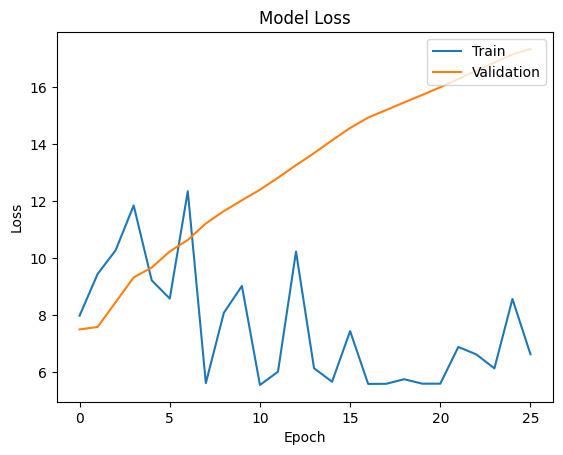

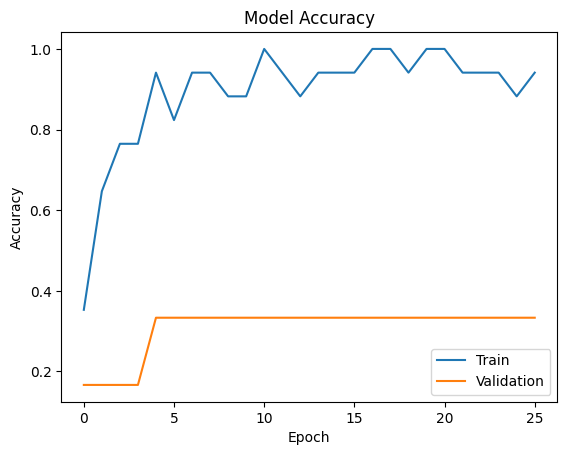

In [39]:
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

## Visualisation of the Results with a Confusion Matrix

1/1 [==============================] - 0s 438ms/step


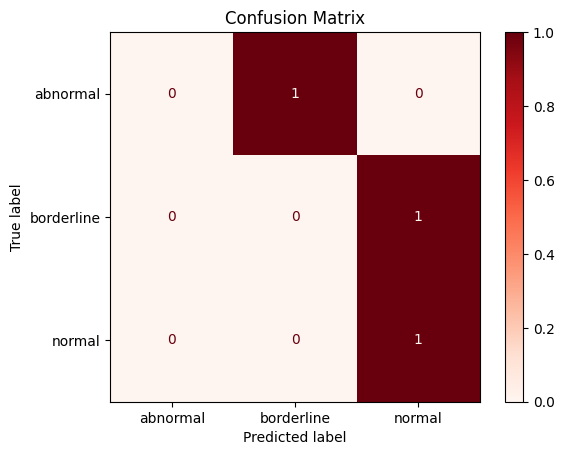

Test accuracy: 0.3333333432674408
Active leads: ['Lead_1', 'Lead_2', 'Lead_3', 'Lead_4']
Test samples evaluated: 3

Classification report:
              precision    recall  f1-score   support

    abnormal       0.00      0.00      0.00         1
  borderline       0.00      0.00      0.00         1
      normal       0.50      1.00      0.67         1

    accuracy                           0.33         3
   macro avg       0.17      0.33      0.22         3
weighted avg       0.17      0.33      0.22         3



In [40]:
# Generate predictions on the test set
y_pred = model.predict(multi_head_inputs(X_test))
y_pred_classes = np.argmax(y_pred, axis=-1)

# Decode predicted classes
y_pred_decoded = label_encoder.inverse_transform(y_pred_classes)

# Decode true labels
y_test_decoded = label_encoder.inverse_transform(y_test_encoded)

# Now, you can use y_test_decoded and y_pred_decoded for the confusion matrix
cm = confusion_matrix(y_test_decoded, y_pred_decoded, labels=label_encoder.classes_)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Reds, values_format="d")
plt.title("Confusion Matrix")
plt.show()

print(f'Test accuracy: {test_acc}')
print("Active leads:", active_leads)
print("Test samples evaluated:", X_test.shape[0])
print("\nClassification report:")
print(classification_report(y_test_decoded, y_pred_decoded, labels=label_encoder.classes_, zero_division=0))

Plot coefficients and see how they convervge. See if any input has not much significance.

## Under Development:

AUC for each class: [0.5 0.5 1. ]


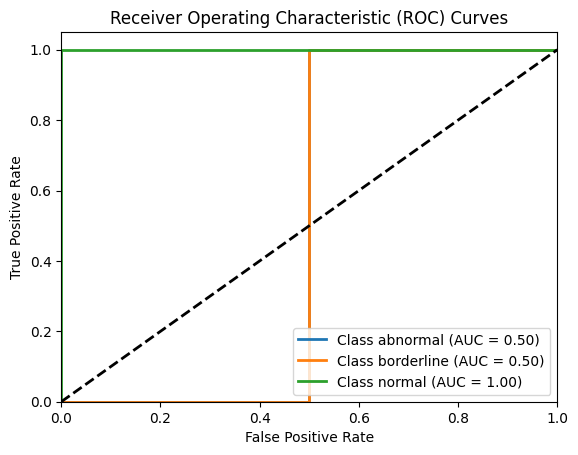

In [41]:
# ROC/AUC section for multiclass abnormal/borderline/normal classification.
y_test_one_hot_for_auc = to_categorical(y_test_encoded, num_classes=classes)

try:
    auc_per_class = roc_auc_score(y_test_one_hot_for_auc, y_pred, average=None)
    print(f"AUC for each class: {auc_per_class}")
except Exception as e:
    print("Could not calculate AUC. This often happens if the test set is missing one or more classes.")
    print(e)

fpr = dict()
tpr = dict()
roc_auc = dict()
n_classes = y_test_one_hot_for_auc.shape[1]

plt.figure()
for i in range(n_classes):
    if len(np.unique(y_test_one_hot_for_auc[:, i])) < 2:
        print(f"Skipping ROC for class {label_encoder.classes_[i]} because test set has only one binary value for this class.")
        continue
    fpr[i], tpr[i], _ = roc_curve(y_test_one_hot_for_auc[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], lw=2, label=f'Class {label_encoder.classes_[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc='lower right')
plt.show()

In [42]:
from sklearn.metrics import f1_score

# Calculate the F1 score for each class
f1_per_class = f1_score(y_test_decoded, y_pred_decoded, labels=label_encoder.classes_, average=None, zero_division=0)

# Print the F1 score for each class
for i, f1 in enumerate(f1_per_class):
    print(f'F1 score for class {label_encoder.classes_[i]}: {f1:.2f}')

F1 score for class abnormal: 0.00
F1 score for class borderline: 0.00
F1 score for class normal: 0.67


In [43]:
# Save model and split manifest.
model.save("final_multi_head_ecg_cnn.keras")

split_manifest = split_preview.copy()
split_manifest.to_csv("ecg_split_manifest.csv", index=False)

metadata = {
    "classes": label_encoder.classes_.tolist(),
    "fixed_length": int(FIXED_LENGTH),
    "expected_leads": EXPECTED_LEADS,
    "active_leads": active_leads,
    "group_id_regex": GROUP_ID_REGEX,
    "test_folders": list(map(str, test_folders)),
    "validation_folders": list(map(str, validation_folders)),
    "test_samples_evaluated": int(X_test.shape[0]),
    "validation_samples": int(X_valid.shape[0]),
    "train_samples": int(X_train.shape[0]),
}

with open("ecg_cnn_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved final_multi_head_ecg_cnn.keras")
print("Saved ecg_split_manifest.csv")
print("Saved ecg_cnn_metadata.json")

Saved final_multi_head_ecg_cnn.keras
Saved ecg_split_manifest.csv
Saved ecg_cnn_metadata.json
